# 02. Features and peer comparison

A prescriber is not suspicious because they write many prescriptions: a busy geriatrician should. What matters is **how unusual their pattern is compared with similar prescribers**. This notebook builds three kinds of features:

1. **Rates and mixes**: what share of claims are opioids, brand-name drugs, or for low-income patients; days of supply per claim; cost per patient. These describe *how* someone prescribes, independent of size.
2. **Volume**: log-scaled counts of claims, patients and cost.
3. **Peer comparisons**: for each rate, how far the prescriber sits from the median of their **specialty** that year, measured in interquartile ranges (a robust z-score that is not distorted by extreme values), plus their percentile within the specialty.

All features use only the same year as the row, so nothing from the future enters.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_processed
from src.features import build_features, PEER_FEATURES

labeled = load_processed("labeled_2022")
feats = build_features(labeled)
print(feats.shape)
feats.head(3).T.head(25)

(1332252, 60)


,0,1,2
log_claims,6.523562,2.772589,4.174387
log_benes,5.768321,NaN,3.583519
log_cost,10.599547,5.428292,5.941749
claims_per_bene,2.131661,NaN,1.828571
days_per_claim,40.405882,38.2,11.578125
fills_per_claim,1.656471,1.566667,1.0
cost_per_claim,58.993618,15.117333,5.93125
cost_per_bene,125.75442,NaN,10.845714
brand_claim_share,0.104412,0.733333,NaN
brand_cost_share,0.763944,0.261598,NaN


## Do positives look different?

For each rate, compare the median among prescribers later excluded (label = any exclusion) with the median among everyone else. A ratio well above 1 means positives tend to be higher on that feature.

Raw medians can mislead because specialties differ (oncologists have high cost per claim for everyone), so we also compare the **peer percentile**: where the prescriber sits within their own specialty. For a random prescriber the median percentile is 0.5.

In [2]:
y = labeled["label_any"].to_numpy()
rows = []
for c in PEER_FEATURES:
    pos, neg = feats.loc[y == 1, c], feats.loc[y == 0, c]
    pct_pos = feats.loc[y == 1, f"{c}_peer_pct"]
    rows.append({"feature": c, "median positives": pos.median(), "median others": neg.median(),
                 "median peer percentile (positives)": pct_pos.median(),
                 "% missing (positives)": pos.isna().mean() * 100})
cmp = pd.DataFrame(rows).set_index("feature")
cmp["ratio"] = cmp["median positives"] / cmp["median others"].replace(0, np.nan)
cmp.sort_values("median peer percentile (positives)", ascending=False).round(3)

,median positives,median others,median peer percentile (positives),% missing (positives),ratio
feature,,,,,
dual_bene_share,0.401,0.289,0.676,45.631,1.385
lis_claim_share,0.462,0.349,0.656,22.330,1.322
opioid_days_per_claim,22.943,12.139,0.648,67.961,1.890
claims_per_bene,4.955,2.959,0.586,16.505,1.674
cost_per_bene,508.918,257.889,0.552,16.505,1.973
cost_per_claim,70.612,65.900,0.529,0.000,1.072
opioid_la_share,0.000,0.000,0.499,78.317,NaN
antipsychotic_claim_share,0.000,0.000,0.498,36.246,NaN
brand_claim_share,0.104,0.117,0.497,40.129,0.890


## Peer percentiles, visually

If the features carried no signal, positives would be spread evenly across peer percentiles (flat histogram). Bars piling up on the right mean positives tend to sit at the top of their specialty.

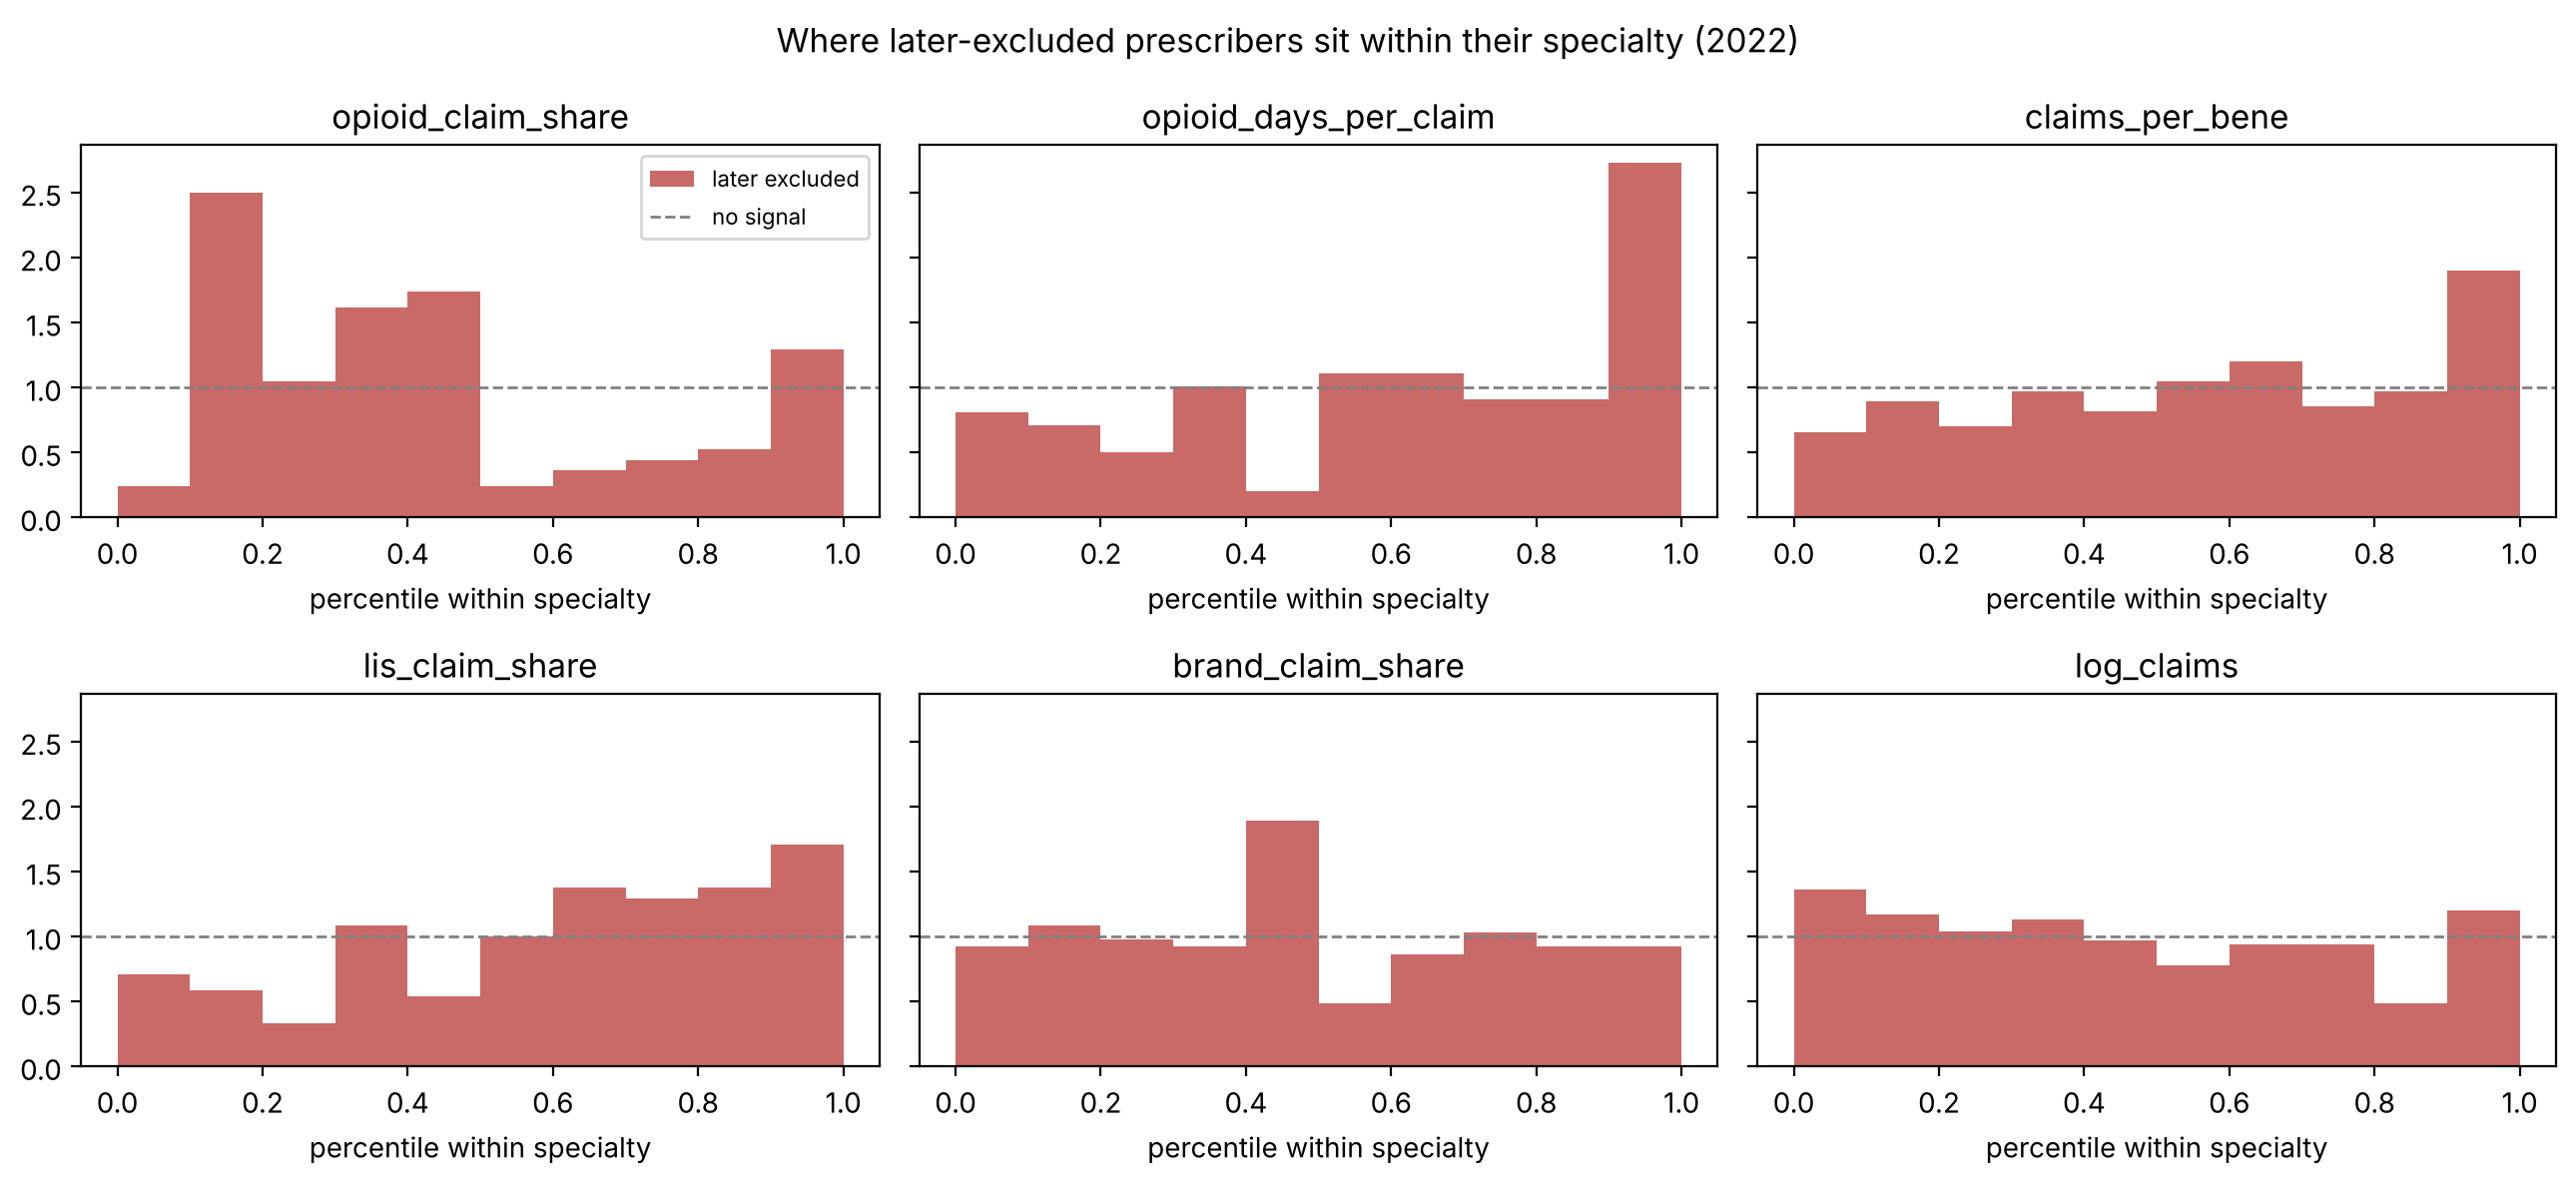

In [3]:
show = ["opioid_claim_share", "opioid_days_per_claim", "claims_per_bene", "lis_claim_share",
        "brand_claim_share", "log_claims"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
for ax, c in zip(axes.ravel(), show):
    ax.hist(feats.loc[y == 1, f"{c}_peer_pct"].dropna(), bins=10, range=(0, 1),
            density=True, color="#c0504d", alpha=.85, label="later excluded")
    ax.axhline(1, color="grey", lw=1, ls="--", label="no signal")
    ax.set_title(c); ax.set_xlabel("percentile within specialty")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Where later-excluded prescribers sit within their specialty (2022)")
fig.tight_layout()

## Suppression as a signal

CMS hides small counts. A prescriber with many suppressed fields has a small Medicare panel. We check whether positives differ in how much of their record is suppressed.

In [4]:
pd.crosstab(feats["n_suppressed"], labeled["label_any"], normalize="columns").round(3) * 100

label_any,0,1
n_suppressed,,
0,22.9,29.8
1,27.4,20.1
2,21.6,19.7
3,14.5,16.8
4,9.4,9.4
5,3.6,3.2
6,0.6,1.0


## Takeaways (2022 features, any-exclusion label)

- **Patient mix is the clearest signal.** Later-excluded prescribers sit high within their specialty on the share of patients who are dual Medicare/Medicaid eligible (median peer percentile 0.68) and on the share of claims for low-income subsidy patients (0.66). This fits known fraud schemes that target patients who pay little or nothing out of pocket, but it also reflects where many legitimate safety-net prescribers practice, so it cannot be used on its own.
- **Intensity per patient, not volume.** Positives write more claims per patient (median 4.96 vs 2.96) and spend more per patient (about 2x), but their total volume is not unusually high for their specialty (median peer percentile of claims 0.43).
- **Opioids are subtler than expected.** The median positive does not prescribe a higher share of opioids than peers; but among those who do prescribe them, days of supply per opioid claim are higher (median 22.9 vs 12.1 days). In the opioid share histogram, the bars below 0.5 are an artifact of ties: most prescribers write no opioids and share the same middle rank; the real signal is the excess of positives in the top decile.
- **Missing data carries information.** Many opioid fields are suppressed for positives, and the suppression pattern differs between groups, so we keep missing values as missing for the models.

These are univariate views; the next notebook tests how well all features together rank prescribers for audit, out of time.